# Experiment 4 - Agentic Content Generation

## Objective and Model Selection

This experiment evaluates two locally deployed language models for an AI-assisted marketing content workflow in the proposed Adobe Express application.

Two models are compared:

- **System A - Qwen3 14B (4-bit):** Selected as the larger model to investigate its ability to follow marketing instructions, generate appropriate content, and identify problems through self-review.
- **System B - Llama 3.1 8B Instruct (4-bit):** Selected as a smaller alternative to evaluate whether comparable content quality can be achieved with lower inference latency and computational requirements.

Both models use MLX-compatible quantised checkpoints for local inference on Apple Silicon.

## Evaluation Plan

The experiment uses 20 controlled marketing briefs covering five fictional product scenarios and four content formats: Instagram captions, LinkedIn posts, email subjects and previews, and product descriptions.

Each model completes the same three-stage workflow:

1. **Generate:** Create an initial marketing draft.
2. **Review:** Evaluate the draft against the original brief.
3. **Revise:** Improve the draft using the generated feedback.

The evaluation compares instruction adherence, output structure, execution time, revision effectiveness, and unsupported marketing claims. Identical briefs and prompts are used to support a consistent comparison.

The goal is to determine the practical trade-offs between content reliability and generation efficiency, rather than assuming that the larger model will perform better.

## Environment Setup

This experiment uses Python and MLX-LM to evaluate language models locally on an Apple Silicon MacBook Pro.

A fixed random seed is used for reproducibility. The software environment and package versions are recorded to make the experimental setup transparent.

Both models will be evaluated sequentially on the same marketing briefs to ensure consistent testing conditions.

In [5]:
# Verify the local environment and record package versions

import sys
import platform
import random
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError

SEED = 42
random.seed(SEED)

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("Processor:", platform.machine())
print("Random seed:", SEED)
print("Project directory:", PROJECT_ROOT)

print("\nInstalled packages:")

for package in ["mlx", "mlx-lm", "pandas", "huggingface-hub"]:
    try:
        print(f"{package}: {version(package)}")
    except PackageNotFoundError:
        print(f"{package}: NOT INSTALLED")

Python: 3.11.18
Platform: macOS-26.6.2-arm64-arm-64bit
Processor: arm64
Random seed: 42
Project directory: /Users/sagun/Desktop/mq/fourth/8410/COMP8410_A1_48930164

Installed packages:
mlx: 0.32.4
mlx-lm: 0.32.2
pandas: 3.1.0
huggingface-hub: 1.33.0


## Marketing Evaluation Briefs

A controlled evaluation set of 20 fictional marketing briefs was created by combining five product scenarios with four content formats: Instagram captions, LinkedIn posts, email subjects and previews, and product descriptions.

Each brief specifies the product, target audience, marketing objective, tone, required phrase, call to action (CTA), and maximum word count.

**Design rationale:** Fictional scenarios provide consistent inputs for both models without relying on real marketing campaigns. Using the same products across different formats also allows us to examine content consistency and format adherence. Product details are deliberately limited to test whether models introduce unsupported information.

The following code constructs the 20 briefs and verifies that all five scenarios and four formats are represented.

In [6]:
# Create 20 reproducible marketing evaluation briefs

import pandas as pd

products = [
    {
        "brand": "Harbour Beans",
        "product": "ready-to-drink cold brew coffee",
        "audience": "university students",
        "objective": "introduce a new coffee flavour",
        "required_phrase": "new cold brew",
        "cta": "Explore the range"
    },
    {
        "brand": "GreenNest",
        "product": "indoor plant starter kit",
        "audience": "first-time plant owners",
        "objective": "encourage beginners to try indoor gardening",
        "required_phrase": "plant starter kit",
        "cta": "Discover the kit"
    },
    {
        "brand": "BrightPath",
        "product": "online design workshop",
        "audience": "early-career professionals",
        "objective": "encourage workshop registrations",
        "required_phrase": "online design workshop",
        "cta": "Register today"
    },
    {
        "brand": "Loop Studio",
        "product": "reusable notebook",
        "audience": "students and creative professionals",
        "objective": "highlight everyday note-taking",
        "required_phrase": "reusable notebook",
        "cta": "Learn more"
    },
    {
        "brand": "TrailDash",
        "product": "guided weekend hiking event",
        "audience": "beginner hikers",
        "objective": "encourage event participation",
        "required_phrase": "weekend hiking",
        "cta": "Join the adventure"
    }
]

formats = [
    {"channel": "Instagram caption", "tone": "friendly", "max_words": 65},
    {"channel": "LinkedIn post", "tone": "professional", "max_words": 95},
    {"channel": "Email subject and preview", "tone": "concise", "max_words": 35},
    {"channel": "Product description", "tone": "informative", "max_words": 80}
]

briefs = []

for product in products:
    for fmt in formats:
        briefs.append({
            "brief_id": f"EX4-{len(briefs) + 1:02d}",
            **product,
            **fmt
        })

briefs_df = pd.DataFrame(briefs)

assert len(briefs_df) == 20
assert briefs_df["brief_id"].is_unique

print("Total evaluation briefs:", len(briefs_df))
print("Product scenarios:", briefs_df["brand"].nunique())
print("Content formats:", briefs_df["channel"].nunique())

display(briefs_df.head())

Total evaluation briefs: 20
Product scenarios: 5
Content formats: 4


,brief_id,brand,product,audience,objective,required_phrase,cta,channel,tone,max_words
0,EX4-01,Harbour Beans,ready-to-drink cold brew coffee,university students,introduce a new coffee flavour,new cold brew,Explore the range,Instagram caption,friendly,65
1,EX4-02,Harbour Beans,ready-to-drink cold brew coffee,university students,introduce a new coffee flavour,new cold brew,Explore the range,LinkedIn post,professional,95
2,EX4-03,Harbour Beans,ready-to-drink cold brew coffee,university students,introduce a new coffee flavour,new cold brew,Explore the range,Email subject and preview,concise,35
3,EX4-04,Harbour Beans,ready-to-drink cold brew coffee,university students,introduce a new coffee flavour,new cold brew,Explore the range,Product description,informative,80
4,EX4-05,GreenNest,indoor plant starter kit,first-time plant owners,encourage beginners to try indoor gardening,plant starter kit,Discover the kit,Instagram caption,friendly,65


## Agentic Content Generation Workflow

A three-stage **Generate → Review → Revise** workflow is used to investigate whether model self-review improves marketing content sufficiently to justify the additional processing time.

1. **Generate:** Produce marketing content using the audience, format, tone and constraints specified in the brief.
2. **Review:** Ask the model to identify instruction violations, unsupported claims and opportunities for improvement.
3. **Revise:** Generate a final version using the original brief and review feedback.

Both models use the same prompt templates and output-token limits for a controlled comparison.

The review is performed by the generating model itself, without external tools or independent feedback. Therefore, the experiment also examines whether self-review can identify and correct the model's own mistakes.

Initial and revised outputs are retained to assess constraint adherence, revision effectiveness and execution time.

In [7]:
# Define the shared generate → review → revise workflow

def build_generate_prompt(brief):
    return f"""
You are an AI marketing content assistant.

Create marketing content using the following brief.

Brand: {brief['brand']}
Product: {brief['product']}
Target audience: {brief['audience']}
Marketing objective: {brief['objective']}
Content format: {brief['channel']}
Tone: {brief['tone']}
Required phrase: {brief['required_phrase']}
Call to action: {brief['cta']}
Maximum words: {brief['max_words']}

Requirements:
- Address the target audience.
- Match the requested format and tone.
- Include the exact required phrase.
- Include the exact call to action.
- Stay within the word limit.
- Do not invent prices, discounts, product features, or statistics.
- For email content, provide a subject and preview.

Return only the marketing content.
""".strip()


def build_review_prompt(brief, draft):
    return f"""
You are a marketing content reviewer.

Review the following draft against its original brief.

Original brief:
{build_generate_prompt(brief)}

Draft:
{draft}

Evaluate:
1. Audience relevance
2. Marketing objective
3. Content format
4. Appropriate tone
5. Required phrase
6. Call to action
7. Word limit
8. Unsupported claims

Identify specific problems and suggest improvements.

Do not rewrite the draft yet.
""".strip()


def build_revision_prompt(brief, draft, feedback):
    return f"""
You are revising marketing content for Adobe Express.

Original brief:
{build_generate_prompt(brief)}

Original draft:
{draft}

Review feedback:
{feedback}

Produce an improved final version.

Address the feedback while meeting every original requirement.
Do not invent unsupported product claims.
Return only the revised marketing content.
""".strip()


# Preview the first brief without running a model
example_brief = briefs_df.iloc[0].to_dict()

print("Brief:", example_brief["brief_id"])
print("\nGENERATE PROMPT:\n")
print(build_generate_prompt(example_brief))

Brief: EX4-01

GENERATE PROMPT:

You are an AI marketing content assistant.

Create marketing content using the following brief.

Brand: Harbour Beans
Product: ready-to-drink cold brew coffee
Target audience: university students
Marketing objective: introduce a new coffee flavour
Content format: Instagram caption
Tone: friendly
Required phrase: new cold brew
Call to action: Explore the range
Maximum words: 65

Requirements:
- Address the target audience.
- Match the requested format and tone.
- Include the exact required phrase.
- Include the exact call to action.
- Stay within the word limit.
- Do not invent prices, discounts, product features, or statistics.
- For email content, provide a subject and preview.

Return only the marketing content.


## Qwen3 14B — Inference Pilot

Before the full evaluation, Qwen3 14B is tested on brief EX4-01 to verify the local inference setup and three-stage workflow.

The model uses its MLX-compatible 4-bit checkpoint with non-thinking mode enabled to focus on direct content generation. Sampling uses temperature 0.7 and top-p 0.8, with token limits of 180 for generation, 300 for review, and 180 for revision.

The pilot records execution time for each stage and retains the original draft, review feedback, and revised output. These are inspected to determine whether self-review identifies unsupported claims and whether revision corrects them before applying the workflow to all 20 briefs.

In [8]:
from mlx_lm import load, generate
import time

MODEL_A_ID = "mlx-community/Qwen3-14B-4bit"

print("Loading Qwen3 14B...")

load_start = time.perf_counter()
qwen_model, qwen_tokenizer = load(MODEL_A_ID)
print(f"Model loading time: {time.perf_counter() - load_start:.2f}s")

Loading Qwen3 14B...


Fetching 10 files: 100%|██████████| 10/10 [00:00<00:00, 3024.01it/s]


Model loading time: 2.73s


In [9]:
# Pilot: Generate the initial draft for brief EX4-01

from mlx_lm.sample_utils import make_sampler
import mlx.core as mx

mx.random.seed(SEED)

brief = briefs_df.iloc[0].to_dict()
generation_prompt = build_generate_prompt(brief)

# Format the prompt using Qwen3's chat template
messages = [
    {"role": "user", "content": generation_prompt}
]

formatted_prompt = qwen_tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True,
    enable_thinking=False
)

sampler = make_sampler(temp=0.7, top_p=0.8)

start = time.perf_counter()

qwen_draft = generate(
    qwen_model,
    qwen_tokenizer,
    prompt=formatted_prompt,
    max_tokens=180,
    sampler=sampler,
    verbose=False
)

generation_time = time.perf_counter() - start

print("Brief:", brief["brief_id"])
print("\nINITIAL DRAFT:\n")
print(qwen_draft)
print(f"\nGeneration time: {generation_time:.2f}s")

Brief: EX4-01

INITIAL DRAFT:

Hey students! ☕️ Fresh out of the fridge — our new cold brew is here to fuel your late-night study sessions. Try the new cold brew flavour and keep your energy high all day long! Explore the range now. #HarbourBeans #NewColdBrew

Generation time: 6.27s


In [10]:
# Pilot: Review the initial Qwen3 14B draft

review_prompt = build_review_prompt(brief, qwen_draft)

review_messages = [
    {"role": "user", "content": review_prompt}
]

formatted_review = qwen_tokenizer.apply_chat_template(
    review_messages,
    tokenize=False,
    add_generation_prompt=True,
    enable_thinking=False
)

start = time.perf_counter()

qwen_feedback = generate(
    qwen_model,
    qwen_tokenizer,
    prompt=formatted_review,
    max_tokens=300,
    sampler=sampler,
    verbose=False
)

review_time = time.perf_counter() - start

print("Brief:", brief["brief_id"])
print("\nREVIEW FEEDBACK:\n")
print(qwen_feedback)
print(f"\nReview time: {review_time:.2f}s")

Brief: EX4-01

REVIEW FEEDBACK:

**Evaluation:**

1. **Audience relevance:** The draft addresses university students by referencing late-night study sessions, which is relevant. However, it could be more specific in connecting with student lifestyle or preferences.

2. **Marketing objective:** The content successfully introduces the new cold brew flavour, aligning with the marketing objective.

3. **Content format:** The draft is in the correct format for an Instagram caption, with a hashtag and appropriate punctuation.

4. **Appropriate tone:** The tone is friendly and approachable, fitting for the target audience.

5. **Required phrase:** The exact required phrase "new cold brew" is included.

6. **Call to action:** The call to action "Explore the range now" is present and appropriate.

7. **Word limit:** The draft is within the 65-word limit.

8. **Unsupported claims:** There are no unsupported claims, such as prices, discounts, or statistics.

**Specific Problems and Suggested Impr

In [11]:
# Pilot: Revise the Qwen3 14B marketing caption

revision_prompt = build_revision_prompt(
    brief,
    qwen_draft,
    qwen_feedback
)

revision_messages = [
    {"role": "user", "content": revision_prompt}
]

formatted_revision = qwen_tokenizer.apply_chat_template(
    revision_messages,
    tokenize=False,
    add_generation_prompt=True,
    enable_thinking=False
)

start = time.perf_counter()

qwen_revised = generate(
    qwen_model,
    qwen_tokenizer,
    prompt=formatted_revision,
    max_tokens=180,
    sampler=sampler,
    verbose=False
)

revision_time = time.perf_counter() - start

print("Brief:", brief["brief_id"])

print("\nORIGINAL DRAFT:\n")
print(qwen_draft)

print("\nREVISED DRAFT:\n")
print(qwen_revised)

print(f"\nRevision time: {revision_time:.2f}s")

print(
    "Total workflow time:",
    round(generation_time + review_time + revision_time, 2),
    "seconds"
)

Brief: EX4-01

ORIGINAL DRAFT:

Hey students! ☕️ Fresh out of the fridge — our new cold brew is here to fuel your late-night study sessions. Try the new cold brew flavour and keep your energy high all day long! Explore the range now. #HarbourBeans #NewColdBrew

REVISED DRAFT:

Hey students! ☕️ Your new cold brew flavour is here to power your classes, late-night cram sessions, and coffee breaks. Try the new cold brew and keep your energy going all day! Explore the range. #HarbourBeans #NewColdBrew

Revision time: 5.08s
Total workflow time: 24.66 seconds


### Pilot Findings and Independent Validation

Qwen3 14B completed the Generate → Review → Revise workflow for EX4-01 in **24.66 seconds**.

Although the model's self-review reported no unsupported claims, the revised caption retained an unverified claim about providing energy throughout the day. This shows that self-review does not necessarily identify or correct factual grounding problems.

To assess instruction adherence independently of the model's feedback, the following code compares the original and revised drafts against three measurable requirements: word limit, exact required phrase, and CTA. These checks do not assess factual reliability or marketing quality.

In [12]:
# Independently check measurable marketing constraints

import re

def check_constraints(brief, content):
    word_count = len(content.split())

    return {
        "Word count": word_count,
        "Within word limit": word_count <= brief["max_words"],
        "Required phrase present": (
            brief["required_phrase"].lower() in content.lower()
        ),
        "CTA present": (
            brief["cta"].lower() in content.lower()
        )
    }

pilot_check = pd.DataFrame({
    "Original": check_constraints(brief, qwen_draft),
    "Revised": check_constraints(brief, qwen_revised)
})

display(pilot_check)

,Original,Revised
Word count,41,37
Within word limit,True,True
Required phrase present,True,True
CTA present,True,True


## Full Qwen3 14B Evaluation

Following the pilot, Qwen3 14B was evaluated on all **20 marketing briefs** to assess its performance across different products, audiences and content formats.

Each brief followed the same Generate → Review → Revise workflow, using identical prompt templates and inference settings. The completed EX4-01 pilot was reused to avoid redundant inference.

For each brief, the evaluation records:

- Initial draft, self-review feedback and revised content.
- Generation, review, revision and total execution times.
- Word-limit, required-phrase and CTA compliance before and after revision.

Results are saved incrementally to `experiment_04_qwen.csv` to preserve completed evaluations.

This provides evidence of instruction adherence, workflow efficiency and whether self-revision improves measurable compliance across different marketing tasks.

In [14]:
# Full Qwen3 14B evaluation — 20 marketing briefs
# Reuse EX4-01 and save results after each new brief

import time
import pandas as pd

output_path = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "infovqa_eval"
    / "experiment_04_qwen.csv"
)

assert output_path.parent.exists(), f"Folder not found: {output_path.parent}"

# Resume any previously saved results
if output_path.exists():
    results = pd.read_csv(output_path).to_dict("records")
else:
    results = []

completed = {row["brief_id"] for row in results}

# Preserve the completed EX4-01 pilot
if "EX4-01" not in completed:
    original_check = check_constraints(brief, qwen_draft)
    revised_check = check_constraints(brief, qwen_revised)

    results.append({
        "brief_id": "EX4-01",
        "channel": brief["channel"],
        "initial_draft": qwen_draft,
        "review_feedback": qwen_feedback,
        "revised_draft": qwen_revised,
        "generation_time_s": round(generation_time, 2),
        "review_time_s": round(review_time, 2),
        "revision_time_s": round(revision_time, 2),
        "total_time_s": round(
            generation_time + review_time + revision_time, 2
        ),
        "original_word_limit": original_check["Within word limit"],
        "original_phrase": original_check["Required phrase present"],
        "original_cta": original_check["CTA present"],
        "revised_word_limit": revised_check["Within word limit"],
        "revised_phrase": revised_check["Required phrase present"],
        "revised_cta": revised_check["CTA present"]
    })

    pd.DataFrame(results).to_csv(output_path, index=False)
    completed.add("EX4-01")


def run_qwen_stage(prompt_text, token_limit):
    messages = [{"role": "user", "content": prompt_text}]

    formatted = qwen_tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False
    )

    start = time.perf_counter()

    text = generate(
        qwen_model,
        qwen_tokenizer,
        prompt=formatted,
        max_tokens=token_limit,
        sampler=sampler,
        verbose=False
    )

    elapsed = time.perf_counter() - start
    return text, elapsed


# Process only briefs not already saved
for _, row in briefs_df.iterrows():

    current_brief = row.to_dict()
    brief_id = current_brief["brief_id"]

    if brief_id in completed:
        continue

    # 1. Generate
    draft, t_generate = run_qwen_stage(
        build_generate_prompt(current_brief),
        180
    )

    # 2. Review
    feedback, t_review = run_qwen_stage(
        build_review_prompt(current_brief, draft),
        300
    )

    # 3. Revise
    revised, t_revise = run_qwen_stage(
        build_revision_prompt(current_brief, draft, feedback),
        180
    )

    original_check = check_constraints(current_brief, draft)
    revised_check = check_constraints(current_brief, revised)

    results.append({
        "brief_id": brief_id,
        "channel": current_brief["channel"],
        "initial_draft": draft,
        "review_feedback": feedback,
        "revised_draft": revised,
        "generation_time_s": round(t_generate, 2),
        "review_time_s": round(t_review, 2),
        "revision_time_s": round(t_revise, 2),
        "total_time_s": round(
            t_generate + t_review + t_revise, 2
        ),
        "original_word_limit": original_check["Within word limit"],
        "original_phrase": original_check["Required phrase present"],
        "original_cta": original_check["CTA present"],
        "revised_word_limit": revised_check["Within word limit"],
        "revised_phrase": revised_check["Required phrase present"],
        "revised_cta": revised_check["CTA present"]
    })

    # Checkpoint after each completed brief
    pd.DataFrame(results).to_csv(output_path, index=False)
    completed.add(brief_id)

    print(
        f"[{len(completed)}/20] {brief_id} completed "
        f"| {t_generate + t_review + t_revise:.2f}s",
        flush=True
    )


qwen_results_df = pd.DataFrame(results).sort_values("brief_id")

assert len(qwen_results_df) == 20

print("\nQwen3 14B evaluation complete: 20/20")
display(qwen_results_df[
    ["brief_id", "channel", "total_time_s",
     "revised_word_limit", "revised_phrase", "revised_cta"]
])

[2/20] EX4-02 completed | 20.35s
[3/20] EX4-03 completed | 17.27s
[4/20] EX4-04 completed | 20.29s
[5/20] EX4-05 completed | 19.21s
[6/20] EX4-06 completed | 18.81s
[7/20] EX4-07 completed | 14.01s
[8/20] EX4-08 completed | 20.45s
[9/20] EX4-09 completed | 19.72s
[10/20] EX4-10 completed | 17.55s
[11/20] EX4-11 completed | 15.35s
[12/20] EX4-12 completed | 19.14s
[13/20] EX4-13 completed | 18.40s
[14/20] EX4-14 completed | 17.63s
[15/20] EX4-15 completed | 15.60s
[16/20] EX4-16 completed | 17.93s
[17/20] EX4-17 completed | 18.07s
[18/20] EX4-18 completed | 21.52s
[19/20] EX4-19 completed | 15.39s
[20/20] EX4-20 completed | 16.88s

Qwen3 14B evaluation complete: 20/20


,brief_id,channel,total_time_s,revised_word_limit,revised_phrase,revised_cta
0,EX4-01,Instagram caption,24.66,True,True,True
1,EX4-02,LinkedIn post,20.35,True,True,True
2,EX4-03,Email subject and preview,17.27,True,True,True
3,EX4-04,Product description,20.29,True,True,True
4,EX4-05,Instagram caption,19.21,True,True,True
5,EX4-06,LinkedIn post,18.81,True,True,True
6,EX4-07,Email subject and preview,14.01,True,True,True
7,EX4-08,Product description,20.45,True,True,True
8,EX4-09,Instagram caption,19.72,True,True,True
9,EX4-10,LinkedIn post,17.55,True,True,True


## Qwen3 14B — Evaluation Results

The completed evaluation is analysed across all 20 marketing briefs.

Initial and revised outputs are compared using three independently checked requirements: word limit, required phrase, and call to action. Average execution times are calculated for each workflow stage.

These automated measurements assess instruction adherence and efficiency, not creativity, factual reliability, or overall marketing quality.

In [15]:
# Summarise Qwen3 14B evaluation results

checks = [
    ("Word limit", "word_limit"),
    ("Required phrase", "phrase"),
    ("Call to action", "cta"),
]

summary_rows = []

for label, suffix in checks:
    original = qwen_results_df[f"original_{suffix}"].astype(bool)
    revised = qwen_results_df[f"revised_{suffix}"].astype(bool)

    summary_rows.append({
        "Requirement": label,
        "Original passed": f"{original.sum()}/20",
        "Revised passed": f"{revised.sum()}/20"
    })

display(pd.DataFrame(summary_rows))

original_all = qwen_results_df[
    ["original_word_limit", "original_phrase", "original_cta"]
].astype(bool).all(axis=1)

revised_all = qwen_results_df[
    ["revised_word_limit", "revised_phrase", "revised_cta"]
].astype(bool).all(axis=1)

print("All three requirements satisfied:")
print(f"Original: {original_all.sum()}/20")
print(f"Revised:  {revised_all.sum()}/20")

print("\nAverage workflow times:")
for col in [
    "generation_time_s",
    "review_time_s",
    "revision_time_s",
    "total_time_s"
]:
    print(f"{col}: {qwen_results_df[col].mean():.2f}s")

print(f"\nImproved compliance: {(~original_all & revised_all).sum()}")
print(f"Worsened compliance: {(original_all & ~revised_all).sum()}")

,Requirement,Original passed,Revised passed
0,Word limit,20/20,20/20
1,Required phrase,20/20,20/20
2,Call to action,20/20,20/20


All three requirements satisfied:
Original: 20/20
Revised:  20/20

Average workflow times:
generation_time_s: 2.84s
review_time_s: 11.11s
revision_time_s: 4.45s
total_time_s: 18.41s

Improved compliance: 0
Worsened compliance: 0


### Key Findings

Qwen3 14B completed all 20 marketing briefs, with both the original and revised drafts satisfying all three automated requirements: word limit, required phrase and CTA (**20/20, 100%**).

The average complete workflow took **18.41 seconds** per brief:

- Generation: 2.84 s
- Review: 11.11 s
- Revision: 4.45 s

The review stage accounted for approximately **60% of total execution time**, making it the most computationally expensive stage.

**Revision effectiveness:** No improvement or deterioration in measurable compliance was observed because all original drafts already satisfied the three requirements. This does not establish whether revision improved content quality.

**Key limitation:** These checks measure basic instruction adherence, not factual reliability, unsupported claims or correct content structure.

## Llama 3.1 8B — Evaluation

Llama 3.1 8B Instruct (4-bit) is evaluated as a smaller, computationally lighter alternative to Qwen3 14B.

The evaluation follows the same experimental procedure, using the identical 20 marketing briefs, prompt templates, sampling parameters, and output-token limits.

An initial pilot on EX4-01 verifies the Generate → Review → Revise workflow before the full evaluation. Both models are assessed using the same independent constraint checks.

This comparison investigates whether the smaller model can provide comparable instruction adherence and content quality with lower inference latency.

In [16]:
# Load Llama 3.1 8B Instruct

from mlx_lm import load
import time

MODEL_B_ID = "mlx-community/Llama-3.1-8B-Instruct-4bit"

print("Loading Llama 3.1 8B...")

start = time.perf_counter()

llama_model, llama_tokenizer = load(MODEL_B_ID)

print(f"Model loading time: {time.perf_counter() - start:.2f}s")

Loading Llama 3.1 8B...


Fetching 6 files: 100%|██████████| 6/6 [00:00<00:00, 1640.32it/s]


Model loading time: 2.92s


In [17]:
# Llama 3.1 8B — Generation pilot (EX4-01)

brief = briefs_df.iloc[0].to_dict()

generation_prompt = build_generate_prompt(brief)

messages = [
    {"role": "user", "content": generation_prompt}
]

formatted_prompt = llama_tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True
)

start = time.perf_counter()

llama_draft = generate(
    llama_model,
    llama_tokenizer,
    prompt=formatted_prompt,
    max_tokens=180,
    sampler=sampler,
    verbose=False
)

llama_generation_time = time.perf_counter() - start

print("Brief:", brief["brief_id"])
print("\nLLAMA INITIAL DRAFT:\n")
print(llama_draft)
print(f"\nGeneration time: {llama_generation_time:.2f}s")

Brief: EX4-01

LLAMA INITIAL DRAFT:

"Hey students, we've got a buzzworthy update for you! Introducing our new cold brew flavour: rich, velvety Vanilla Chai! It's the perfect pick-me-up for those long study sessions. Try it out and explore the range! #HarbourBeans #NewColdBrew"

Generation time: 2.85s


In [18]:
# Llama 3.1 8B — Review pilot (EX4-01)

llama_review_prompt = build_review_prompt(
    brief,
    llama_draft
)

messages = [
    {"role": "user", "content": llama_review_prompt}
]

formatted_review = llama_tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True
)

start = time.perf_counter()

llama_feedback = generate(
    llama_model,
    llama_tokenizer,
    prompt=formatted_review,
    max_tokens=300,
    sampler=sampler,
    verbose=False
)

llama_review_time = time.perf_counter() - start

print("Brief:", brief["brief_id"])
print("\nLLAMA REVIEW FEEDBACK:\n")
print(llama_feedback)
print(f"\nReview time: {llama_review_time:.2f}s")

Brief: EX4-01

LLAMA REVIEW FEEDBACK:

Evaluation:

1. **Audience relevance**: The draft is highly relevant to the target audience, university students. It mentions study sessions, which directly appeals to their needs.

2. **Marketing objective**: The draft partially meets the marketing objective of introducing a new coffee flavour. However, it doesn't specifically focus on the new flavour, but rather the entire cold brew product.

3. **Content format**: The draft matches the required format of an Instagram caption.

4. **Appropriate tone**: The tone is friendly, which meets the requirements.

5. **Required phrase**: The exact phrase "new cold brew" is included in the draft.

6. **Call to action**: The call to action "Explore the range" matches the required phrase.

7. **Word limit**: The draft stays within the 65-word limit.

8. **Unsupported claims**: The draft makes claims about the product being a "perfect pick-me-up" and "buzzworthy," which aren't explicitly stated in the brief a

In [19]:
# Llama 3.1 8B — Revision pilot (EX4-01)

llama_revision_prompt = build_revision_prompt(
    brief,
    llama_draft,
    llama_feedback
)

messages = [
    {"role": "user", "content": llama_revision_prompt}
]

formatted_revision = llama_tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True
)

start = time.perf_counter()

llama_revised = generate(
    llama_model,
    llama_tokenizer,
    prompt=formatted_revision,
    max_tokens=180,
    sampler=sampler,
    verbose=False
)

llama_revision_time = time.perf_counter() - start

print("Brief:", brief["brief_id"])

print("\nORIGINAL DRAFT:\n")
print(llama_draft)

print("\nREVISED DRAFT:\n")
print(llama_revised)

print(f"\nRevision time: {llama_revision_time:.2f}s")

llama_total_time = (
    llama_generation_time
    + llama_review_time
    + llama_revision_time
)

print(f"Total workflow time: {llama_total_time:.2f}s")

Brief: EX4-01

ORIGINAL DRAFT:

"Hey students, we've got a buzzworthy update for you! Introducing our new cold brew flavour: rich, velvety Vanilla Chai! It's the perfect pick-me-up for those long study sessions. Try it out and explore the range! #HarbourBeans #NewColdBrew"

REVISED DRAFT:

"Hey students, we've got a new cold brew that's worth trying! Introducing our Vanilla Chai flavour, a delicious twist on our classic cold brew. Perfect for study sessions or anytime you need a pick-me-up. Explore the range and discover more! #HarbourBeans #NewColdBrew"

Revision time: 3.17s
Total workflow time: 12.92s


### Llama Pilot Findings

Llama 3.1 8B completed the Generate → Review → Revise workflow for EX4-01 in **12.92 seconds**, compared with 24.66 seconds for the Qwen pilot.

The initial caption followed the required Instagram format, included the specified phrase and CTA, and addressed university students. However, it invented a **"Vanilla Chai"** flavour that was not provided in the brief.

During self-review, Llama identified some unsupported promotional language but failed to recognise the invented flavour. The revised caption retained this detail and introduced an additional reference to a "classic cold brew".

**Key finding:** Although Llama completed the workflow faster, its self-review did not prevent unsupported product information from appearing in the final content. This reinforces the need for independent validation.

## Full Llama 3.1 8B Evaluation

Following the pilot, Llama 3.1 8B was evaluated on the same **20 marketing briefs** used for Qwen3 14B.

The experiment uses identical prompt templates, sampling settings, token limits, and independent constraint checks to support a consistent comparison. The completed EX4-01 pilot is reused rather than repeated.

For each brief, the workflow records the initial draft, self-review feedback, revised content, and execution time for each stage. Word-limit, required-phrase, and CTA compliance are checked before and after revision.

Results are saved incrementally to `experiment_04_llama.csv`.

The collected results will be used to compare instruction adherence, revision effectiveness, and inference efficiency between the two models.

In [20]:
# Full Llama 3.1 8B evaluation — 20 briefs

output_path = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "infovqa_eval"
    / "experiment_04_llama.csv"
)

assert output_path.parent.exists(), f"Folder not found: {output_path.parent}"

# Load previous results if the evaluation was interrupted
if output_path.exists():
    llama_results = pd.read_csv(output_path).to_dict("records")
else:
    llama_results = []

completed = {row["brief_id"] for row in llama_results}

# Reuse the completed EX4-01 pilot
if "EX4-01" not in completed:

    pilot_brief = briefs_df.iloc[0].to_dict()

    original_check = check_constraints(pilot_brief, llama_draft)
    revised_check = check_constraints(pilot_brief, llama_revised)

    llama_results.append({
        "brief_id": "EX4-01",
        "channel": pilot_brief["channel"],
        "initial_draft": llama_draft,
        "review_feedback": llama_feedback,
        "revised_draft": llama_revised,
        "generation_time_s": round(llama_generation_time, 2),
        "review_time_s": round(llama_review_time, 2),
        "revision_time_s": round(llama_revision_time, 2),
        "total_time_s": round(llama_total_time, 2),
        "original_word_limit": original_check["Within word limit"],
        "original_phrase": original_check["Required phrase present"],
        "original_cta": original_check["CTA present"],
        "revised_word_limit": revised_check["Within word limit"],
        "revised_phrase": revised_check["Required phrase present"],
        "revised_cta": revised_check["CTA present"]
    })

    pd.DataFrame(llama_results).to_csv(output_path, index=False)
    completed.add("EX4-01")


def run_llama_stage(prompt_text, token_limit):
    messages = [{"role": "user", "content": prompt_text}]

    formatted_prompt = llama_tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    start = time.perf_counter()

    response = generate(
        llama_model,
        llama_tokenizer,
        prompt=formatted_prompt,
        max_tokens=token_limit,
        sampler=sampler,
        verbose=False
    )

    elapsed = time.perf_counter() - start

    return response, elapsed


# Process the remaining briefs
for _, row in briefs_df.iterrows():

    current_brief = row.to_dict()
    brief_id = current_brief["brief_id"]

    if brief_id in completed:
        continue

    # Stage 1 — Generate
    draft, t_generate = run_llama_stage(
        build_generate_prompt(current_brief),
        180
    )

    # Stage 2 — Review
    feedback, t_review = run_llama_stage(
        build_review_prompt(current_brief, draft),
        300
    )

    # Stage 3 — Revise
    revised, t_revise = run_llama_stage(
        build_revision_prompt(current_brief, draft, feedback),
        180
    )

    # Independent constraint checks
    original_check = check_constraints(current_brief, draft)
    revised_check = check_constraints(current_brief, revised)

    llama_results.append({
        "brief_id": brief_id,
        "channel": current_brief["channel"],
        "initial_draft": draft,
        "review_feedback": feedback,
        "revised_draft": revised,
        "generation_time_s": round(t_generate, 2),
        "review_time_s": round(t_review, 2),
        "revision_time_s": round(t_revise, 2),
        "total_time_s": round(
            t_generate + t_review + t_revise, 2
        ),
        "original_word_limit": original_check["Within word limit"],
        "original_phrase": original_check["Required phrase present"],
        "original_cta": original_check["CTA present"],
        "revised_word_limit": revised_check["Within word limit"],
        "revised_phrase": revised_check["Required phrase present"],
        "revised_cta": revised_check["CTA present"]
    })

    # Save progress after each completed brief
    pd.DataFrame(llama_results).to_csv(output_path, index=False)
    completed.add(brief_id)

    print(
        f"[{len(completed)}/20] {brief_id} completed "
        f"| {t_generate + t_review + t_revise:.2f}s",
        flush=True
    )


llama_results_df = (
    pd.DataFrame(llama_results)
    .sort_values("brief_id")
    .reset_index(drop=True)
)

assert len(llama_results_df) == 20

print("\nLlama 3.1 8B evaluation complete: 20/20")

display(llama_results_df[
    [
        "brief_id",
        "channel",
        "total_time_s",
        "revised_word_limit",
        "revised_phrase",
        "revised_cta"
    ]
])

[2/20] EX4-02 completed | 13.36s
[3/20] EX4-03 completed | 9.74s
[4/20] EX4-04 completed | 12.44s
[5/20] EX4-05 completed | 11.38s
[6/20] EX4-06 completed | 12.56s
[7/20] EX4-07 completed | 10.39s
[8/20] EX4-08 completed | 13.17s
[9/20] EX4-09 completed | 11.87s
[10/20] EX4-10 completed | 12.78s
[11/20] EX4-11 completed | 9.56s
[12/20] EX4-12 completed | 12.25s
[13/20] EX4-13 completed | 10.47s
[14/20] EX4-14 completed | 11.78s
[15/20] EX4-15 completed | 10.56s
[16/20] EX4-16 completed | 11.75s
[17/20] EX4-17 completed | 11.47s
[18/20] EX4-18 completed | 10.97s
[19/20] EX4-19 completed | 9.13s
[20/20] EX4-20 completed | 12.12s

Llama 3.1 8B evaluation complete: 20/20


,brief_id,channel,total_time_s,revised_word_limit,revised_phrase,revised_cta
0,EX4-01,Instagram caption,12.92,True,True,True
1,EX4-02,LinkedIn post,13.36,True,True,True
2,EX4-03,Email subject and preview,9.74,True,True,True
3,EX4-04,Product description,12.44,True,True,True
4,EX4-05,Instagram caption,11.38,True,True,True
5,EX4-06,LinkedIn post,12.56,True,True,True
6,EX4-07,Email subject and preview,10.39,True,True,True
7,EX4-08,Product description,13.17,True,True,True
8,EX4-09,Instagram caption,11.87,True,True,True
9,EX4-10,LinkedIn post,12.78,True,True,True


## Model Comparison — Qwen3 14B vs Llama 3.1 8B

The two models are compared using the same 20 marketing briefs and three-stage workflow. The analysis examines initial and revised instruction adherence, average execution times, and whether revision improved measurable compliance.

Content quality and unsupported claims will be examined separately because the automated constraints cannot fully assess these characteristics.

In [21]:
# Compare Qwen3 14B and Llama 3.1 8B

models = {
    "Qwen3 14B": qwen_results_df,
    "Llama 3.1 8B": llama_results_df
}

def count_all_constraints(df, stage):
    columns = [
        f"{stage}_word_limit",
        f"{stage}_phrase",
        f"{stage}_cta"
    ]
    checks = df[columns].astype(str).apply(
        lambda col: col.str.lower().eq("true")
    )
    return int(checks.all(axis=1).sum())

comparison = []

for model_name, df in models.items():
    comparison.append({
        "Model": model_name,
        "Original passed": count_all_constraints(df, "original"),
        "Revised passed": count_all_constraints(df, "revised"),
        "Generation (s)": df["generation_time_s"].mean(),
        "Review (s)": df["review_time_s"].mean(),
        "Revision (s)": df["revision_time_s"].mean(),
        "Total (s)": df["total_time_s"].mean()
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(2))

qwen_avg = qwen_results_df["total_time_s"].mean()
llama_avg = llama_results_df["total_time_s"].mean()

print(f"\nQwen average workflow: {qwen_avg:.2f}s")
print(f"Llama average workflow: {llama_avg:.2f}s")
print(f"Llama speed advantage: {qwen_avg / llama_avg:.2f}x")

,Model,Original passed,Revised passed,Generation (s),Review (s),Revision (s),Total (s)
0,Qwen3 14B,20,20,2.84,11.11,4.45,18.41
1,Llama 3.1 8B,18,20,2.02,6.67,2.84,11.53



Qwen average workflow: 18.41s
Llama average workflow: 11.53s
Llama speed advantage: 1.60x


### Workflow Execution Time

The following stacked bar chart compares the average generation, review and revision times across the 20 briefs for each model. This shows both the overall latency difference and the contribution of each stage to total execution time.

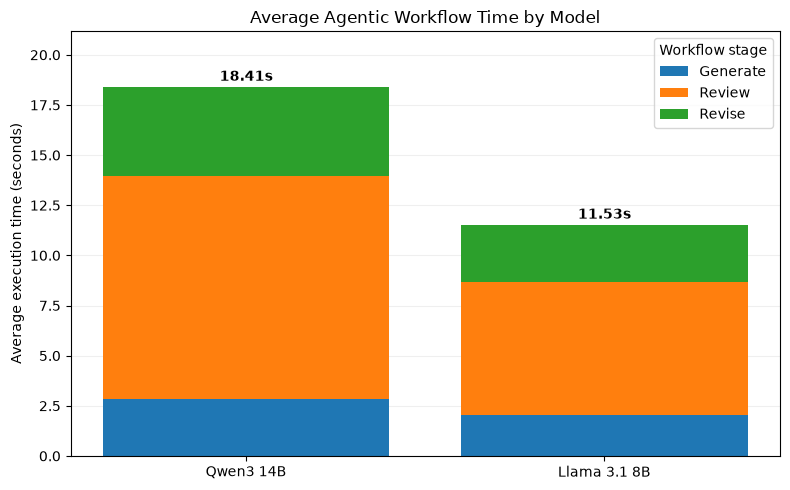

In [33]:
# Compare average execution time by workflow stage

import numpy as np
import matplotlib.pyplot as plt

stages = [
    ("Generation (s)", "Generate"),
    ("Review (s)", "Review"),
    ("Revision (s)", "Revise")
]

models = comparison_df["Model"]
bottom = np.zeros(len(models))

fig, ax = plt.subplots(figsize=(8, 5))

for column, label in stages:
    values = comparison_df[column].to_numpy(dtype=float)

    ax.bar(
        models,
        values,
        bottom=bottom,
        label=label
    )

    bottom += values

for i, total in enumerate(bottom):
    ax.text(
        i,
        total + 0.3,
        f"{total:.2f}s",
        ha="center",
        fontweight="bold"
    )

ax.set_title("Average Agentic Workflow Time by Model")
ax.set_ylabel("Average execution time (seconds)")
ax.set_ylim(0, max(bottom) * 1.15)
ax.legend(title="Workflow stage")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### Execution-Time Findings

Across 20 marketing briefs, **Llama 3.1 8B completed the three-stage workflow 1.60× faster** than Qwen3 14B, averaging 11.53 seconds compared with 18.41 seconds per brief.

The review stage was the largest contributor to execution time for both models. For Qwen, reviewing alone averaged 11.11 seconds, approximately 60% of its total workflow time.

These results highlight the computational cost of model self-review. Although Llama offers lower latency, execution speed alone does not establish better content quality or reliability.

**Key finding:** Llama is more efficient under the tested local inference conditions, but the value of the additional review and revision stages must be considered alongside their ability to improve the generated content.

## Qualitative Content Review

Automated constraint checks do not measure whether generated marketing content is accurate, persuasive, appropriate for the target audience, or free from unsupported claims.

To complement the quantitative evaluation, revised outputs from both models are compared using representative briefs across the four content formats. The review focuses on content relevance, marketing quality, and unsupported product details.

In [22]:
# Compare revised outputs for all four marketing formats

sample_ids = ["EX4-01", "EX4-02", "EX4-03", "EX4-04"]

qwen_sample = qwen_results_df[
    qwen_results_df["brief_id"].isin(sample_ids)
][["brief_id", "revised_draft"]].rename(
    columns={"revised_draft": "Qwen3 14B"}
)

llama_sample = llama_results_df[
    llama_results_df["brief_id"].isin(sample_ids)
][["brief_id", "revised_draft"]].rename(
    columns={"revised_draft": "Llama 3.1 8B"}
)

paired_outputs = (
    briefs_df[briefs_df["brief_id"].isin(sample_ids)]
    [["brief_id", "channel", "product", "objective"]]
    .merge(qwen_sample, on="brief_id")
    .merge(llama_sample, on="brief_id")
)

for _, row in paired_outputs.iterrows():
    print("=" * 70)
    print(f"{row['brief_id']} — {row['channel']}")
    print(f"Product: {row['product']}")
    print(f"Objective: {row['objective']}")

    print("\nQWEN3 14B:\n")
    print(row["Qwen3 14B"])

    print("\nLLAMA 3.1 8B:\n")
    print(row["Llama 3.1 8B"])
    print()

EX4-01 — Instagram caption
Product: ready-to-drink cold brew coffee
Objective: introduce a new coffee flavour

QWEN3 14B:

Hey students! ☕️ Your new cold brew flavour is here to power your classes, late-night cram sessions, and coffee breaks. Try the new cold brew and keep your energy going all day! Explore the range. #HarbourBeans #NewColdBrew

LLAMA 3.1 8B:

"Hey students, we've got a new cold brew that's worth trying! Introducing our Vanilla Chai flavour, a delicious twist on our classic cold brew. Perfect for study sessions or anytime you need a pick-me-up. Explore the range and discover more! #HarbourBeans #NewColdBrew"

EX4-02 — LinkedIn post
Product: ready-to-drink cold brew coffee
Objective: introduce a new coffee flavour

QWEN3 14B:

Harbour Beans is excited to introduce a new cold brew flavour, perfect for university students powering through late-night study sessions. Our latest blend offers a bold, smooth taste to keep you energised and focused. Explore the range to find yo

### Qualitative Findings

A qualitative inspection was conducted on four representative marketing formats (EX4-01 to EX4-04) for the Harbour Beans product scenario.

**Instruction adherence:** Both models satisfied the automatically evaluated requirements, including word limit, required phrase, and call to action. However, both generated email-style subject and preview headings in EX4-04, despite the requested product description format.

**Unsupported content:** Qwen3 14B introduced unsupported claims about taste, energy, and concentration. Llama 3.1 8B generated more specific invented product information, including the flavour names "Vanilla Chai", "Mocha Madness", and "Midnight Eclipse". These details were not supplied in the original brief.

**Self-review effectiveness:** The EX4-01 pilot demonstrated that both models failed to identify or remove important unsupported claims during their generate–review–revise workflows.

**Efficiency:** Llama completed the full workflow in an average of 11.53 seconds per brief, compared with 18.41 seconds for Qwen3 14B, making Llama approximately 1.60 times faster.

**Limitations:** The qualitative assessment covered four outputs from one product scenario, rather than all 20 briefs. Therefore, the observed differences in factual grounding cannot be generalised to the entire evaluation without further inspection.

Overall, the results demonstrate that automatic constraint compliance and execution speed are insufficient measures of marketing content quality. Human review or independent content validation would be necessary before generated content is published.

### Cross-Product Qualitative Review

To examine whether the findings extend beyond the Harbour Beans scenario, four additional briefs are selected, one from each remaining product scenario and marketing format.

The revised outputs are inspected for audience relevance, correct format, unsupported product details, and overall suitability for publication. This review uses previously generated results without additional model inference.

In [35]:
# Compare revised content across different product scenarios

def show_cross_product_pair(brief_id):
    brief_row = briefs_df.loc[
        briefs_df["brief_id"] == brief_id
    ].iloc[0]

    qwen_row = qwen_results_df.loc[
        qwen_results_df["brief_id"] == brief_id
    ].iloc[0]

    llama_row = llama_results_df.loc[
        llama_results_df["brief_id"] == brief_id
    ].iloc[0]

    print(f"BRIEF: {brief_id}")
    print(f"Brand: {brief_row['brand']}")
    print(f"Product: {brief_row['product']}")
    print(f"Audience: {brief_row['audience']}")
    print(f"Objective: {brief_row['objective']}")
    print(f"Format: {brief_row['channel']}")
    print(f"Required phrase: {brief_row['required_phrase']}")
    print(f"CTA: {brief_row['cta']}")

    print("\n" + "=" * 60)
    print("QWEN3 14B — REVISED CONTENT\n")
    print(qwen_row["revised_draft"])

    print("\n" + "=" * 60)
    print("LLAMA 3.1 8B — REVISED CONTENT\n")
    print(llama_row["revised_draft"])


show_cross_product_pair("EX4-05")


BRIEF: EX4-05
Brand: GreenNest
Product: indoor plant starter kit
Audience: first-time plant owners
Objective: encourage beginners to try indoor gardening
Format: Instagram caption
Required phrase: plant starter kit
CTA: Discover the kit

QWEN3 14B — REVISED CONTENT

Hey green thumbs-in-the-making! 🌿 Ready to bring some life into your space? Our plant starter kit is the perfect way to begin your indoor gardening journey. No experience needed—just curiosity and a love for plants. Discover the kit and grow with confidence! 🌱 #GreenNest #PlantLovers

LLAMA 3.1 8B — REVISED CONTENT

"Hey first-time plant lovers! Ready to give indoor gardening a try? Our plant starter kit has got you covered. It's the perfect place to start growing your own green friends. Discover the kit #GreenNest #PlantStarterKit"


In [28]:
show_cross_product_pair("EX4-10")

BRIEF: EX4-10
Brand: BrightPath
Product: online design workshop
Audience: early-career professionals
Objective: encourage workshop registrations
Format: LinkedIn post
Required phrase: online design workshop
CTA: Register today

QWEN3 14B — REVISED CONTENT

Early-career professionals, unlock your creative potential with our **online design workshop**. Develop the skills to craft impactful visual content that stands out in today’s competitive job market. This workshop is tailored to help you grow professionally and confidently. **Register today** and invest in your future.

LLAMA 3.1 8B — REVISED CONTENT

Take your design career off the ground with BrightPath's online design workshop. 

As a recent design graduate or entry-level professional, this workshop is designed to give you a solid foundation and the skills to excel in the industry. Join our expert instructors and learn from industry best practices.

Boost your portfolio and confidence with every project. Stand out in the competiti

In [29]:
show_cross_product_pair("EX4-15")

BRIEF: EX4-15
Brand: Loop Studio
Product: reusable notebook
Audience: students and creative professionals
Objective: highlight everyday note-taking
Format: Email subject and preview
Required phrase: reusable notebook
CTA: Learn more

QWEN3 14B — REVISED CONTENT

Subject: Reusable Notebook for Smarter Note-Taking  

Preview: Students and creatives, streamline everyday notes with our reusable notebook. Learn more.

LLAMA 3.1 8B — REVISED CONTENT

Subject: Take Your Notes Anytime
Preview: Make the most of your reusable notebook, designed for students and creative professionals, where ideas can be erased and reused. Learn more.


In [30]:
show_cross_product_pair("EX4-20")

BRIEF: EX4-20
Brand: TrailDash
Product: guided weekend hiking event
Audience: beginner hikers
Objective: encourage event participation
Format: Product description
Required phrase: weekend hiking
CTA: Join the adventure

QWEN3 14B — REVISED CONTENT

Perfect for beginner hikers, TrailDash offers a guided weekend hiking experience to explore nature with confidence. Learn the trails at your own pace, led by expert guides. Don’t miss your chance—Join the adventure!

LLAMA 3.1 8B — REVISED CONTENT

Subject: Get Ready for Your First Weekend Hiking Experience

Preview: Ready to take the first step? 

Discover TrailDash, a guided weekend hiking event designed for beginner hikers. Our experienced guides will lead you through local trails, teaching essential hiking skills and sharing insights. The weekend hiking experience will be a great opportunity to build confidence and connect with nature. Join the adventure.


### Cross-Product Findings

Four additional briefs (EX4-05, EX4-10, EX4-15 and EX4-20) were inspected to assess whether the issues observed with Harbour Beans also appeared across other products.

| Brief | Qwen3 14B | Llama 3.1 8B |
|---|---|---|
| EX4-05 — Plant starter kit | Engaging, beginner-focused caption | Concise and relevant; neither model invented specific kit components |
| EX4-10 — Design workshop | Professional tone with some unsupported learning benefits | Invented expert instructors, projects and portfolio-related benefits |
| EX4-15 — Reusable notebook | Concise email closely aligned with the brief | Assumed a particular erase-and-reuse functionality |
| EX4-20 — Hiking event | Correct format but unsupported guide qualifications | Incorrect email-style format and unsupported event details |

**Key findings:**

- Both models generally addressed the intended audiences and maintained appropriate marketing tones.
- Qwen tended to use more restrained product descriptions, while Llama introduced more specific unsupported details in several inspected examples.
- The GreenNest example showed that both models could produce relevant content without inventing specific product features.
- Content reliability varied across scenarios, demonstrating that performance cannot be judged from a single marketing brief.

Across the eight manually inspected briefs, Qwen generally stayed closer to the supplied information, although neither model consistently avoided unsupported claims.

**Limitation:** These observations are based on selected examples rather than a systematic factual assessment of all 20 briefs.

### Content Structure Compliance

The initial evaluation checks word limits, required phrases and CTAs, but does not verify whether outputs follow the requested content structure.

An additional rule-based evaluation checks:
- **Email content:** Whether both `Subject:` and `Preview:` headings are present.
- **Product descriptions:** Whether unnecessary email headings are absent.

The following code identifies structure violations across both models. A grouped bar chart then compares compliance across the two content formats.

In [ ]:
def has_heading(text, heading):
    return bool(re.search(
        rf"(?im)^\s*{heading}\s*:",
        str(text)
    ))

format_results = []

for model_name, df in {
    "Qwen3 14B": qwen_results_df,
    "Llama 3.1 8B": llama_results_df
}.items():

    for _, row in df.iterrows():

        channel = row["channel"]
        content = row["revised_draft"]

        subject = has_heading(content, "Subject")
        preview = has_heading(content, "Preview")

        if channel == "Email subject and preview":
            passed = subject and preview

        elif channel == "Product description":
            passed = not (subject or preview)

        else:
            continue

        format_results.append({
            "Model": model_name,
            "Brief": row["brief_id"],
            "Format": channel,
            "Structure passed": passed
        })

format_df = pd.DataFrame(format_results)

print("STRUCTURE CHECK SUMMARY")
display(
    format_df.groupby(["Model", "Format"])["Structure passed"]
    .agg(["sum", "count"])
    .reset_index()
)

print("\nBRIEFS WITH STRUCTURE ERRORS")
display(format_df[~format_df["Structure passed"]])

STRUCTURE CHECK SUMMARY


,Model,Format,sum,count
0,Llama 3.1 8B,Email subject and preview,4,5
1,Llama 3.1 8B,Product description,0,5
2,Qwen3 14B,Email subject and preview,5,5
3,Qwen3 14B,Product description,2,5



BRIEFS WITH STRUCTURE ERRORS


,Model,Brief,Format,Structure passed
1,Qwen3 14B,EX4-04,Product description,False
3,Qwen3 14B,EX4-08,Product description,False
5,Qwen3 14B,EX4-12,Product description,False
11,Llama 3.1 8B,EX4-04,Product description,False
12,Llama 3.1 8B,EX4-07,Email subject and preview,False
13,Llama 3.1 8B,EX4-08,Product description,False
15,Llama 3.1 8B,EX4-12,Product description,False
17,Llama 3.1 8B,EX4-16,Product description,False
19,Llama 3.1 8B,EX4-20,Product description,False


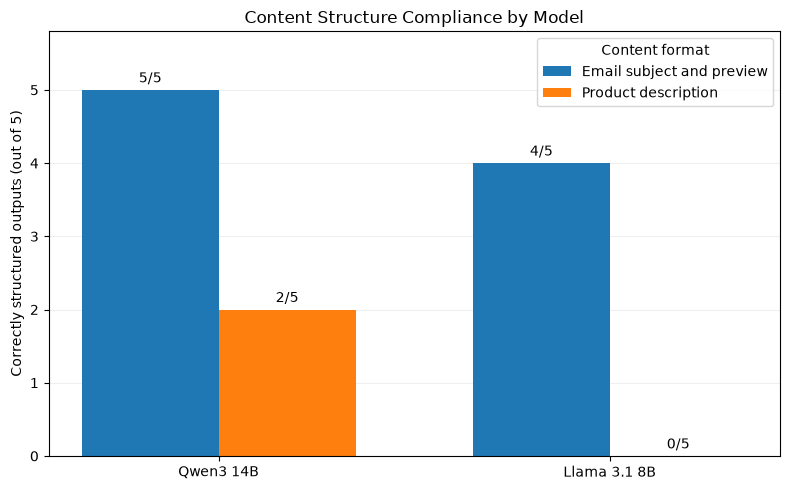

In [34]:
# Compare content structure compliance across both models

model_names = ["Qwen3 14B", "Llama 3.1 8B"]
formats = ["Email subject and preview", "Product description"]

structure_summary = (
    format_df.groupby(["Model", "Format"])["Structure passed"]
    .sum()
    .unstack()
    .reindex(index=model_names, columns=formats)
    .fillna(0)
)

x = np.arange(len(model_names))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

for i, content_format in enumerate(formats):
    values = structure_summary[content_format].to_numpy(dtype=int)

    bars = ax.bar(
        x + (i - 0.5) * width,
        values,
        width,
        label=content_format
    )

    ax.bar_label(
        bars,
        labels=[f"{v}/5" for v in values],
        padding=3
    )

ax.set_title("Content Structure Compliance by Model")
ax.set_ylabel("Correctly structured outputs (out of 5)")
ax.set_xticks(x)
ax.set_xticklabels(model_names)
ax.set_ylim(0, 5.8)
ax.set_yticks(range(6))
ax.legend(title="Content format")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### Content Structure Findings

The additional structure checks revealed errors that were not captured by the initial automated evaluation.

- **Qwen3 14B:** Passed 7/10 checks (70%). All five emails contained the expected headings, but three product descriptions incorrectly included email-style headings.
- **Llama 3.1 8B:** Passed 4/10 checks (40%). One email lacked the expected structure, and all five product descriptions contained unnecessary email headings.

**Key finding:** Although both models achieved 100% compliance with the original word-limit, required-phrase and CTA checks, Qwen performed better on the additional content structure checks.

These results demonstrate that instruction adherence depends on which requirements are measured. The structure checks only examine the presence or absence of specific headings and do not represent a complete assessment of content quality.

## Final Evaluation and Key Findings

The evaluation compared Qwen3 14B and Llama 3.1 8B across 20 marketing briefs using the same Generate → Review → Revise workflow.

**Key findings:**

- **Instruction adherence:** Both models achieved 100% compliance with the three automated constraints (word limit, required phrase and CTA) in their revised outputs.
- **Execution efficiency:** Llama averaged 11.53 seconds per complete workflow, compared with 18.41 seconds for Qwen, making it approximately 1.60× faster.
- **Content structure:** Qwen passed 7/10 additional structure checks, compared with 4/10 for Llama. Product descriptions were a particular weakness for both models.
- **Content reliability:** Qualitative inspection of eight briefs revealed unsupported claims in both models' outputs. Llama frequently introduced specific product details that were absent from the original briefs.
- **Self-review effectiveness:** Qwen satisfied all three automated constraints before and after revision (20/20), while Llama improved from 18/20 to 20/20. This demonstrates that self-revision can correct measurable instruction violations. However, the EX4-01 pilots showed that both models could retain unsupported product claims despite completing the review and revision stages.

**Overall assessment:** Qwen3 14B is the stronger candidate when content structure and adherence to supplied product information are prioritised. Llama 3.1 8B offers better inference efficiency but showed more unsupported product details in the inspected examples.

For the proposed Adobe Express application, neither model should publish marketing content without validation against approved product information. Human review remains necessary, particularly for product claims.

**Limitations:** The evaluation used 20 fictional briefs, with only eight selected for qualitative inspection. The findings are specific to the tested models, quantisation settings and local hardware. The automated checks do not provide a comprehensive measure of creativity, factual accuracy or marketing effectiveness.